# 📉 Prédiction du churn (départ des clients) – Tunisie Télécom

**Auteure : Malak Saidani**

Ce notebook montre, étape par étape, comment prédire si un client va **quitter son opérateur** (c'est le *churn*).

### Plan du notebook
1. Objectif du projet
2. Importation des bibliothèques
3. Chargement des données
4. Exploration des données
5. Analyse de la variable cible (`churn`)
6. Analyse des variables (graphiques)
7. Préparation des données
8. Modélisation (4 modèles)
9. Comparaison des modèles
10. Courbes d'apprentissage
11. Variables les plus importantes
12. Sauvegarde du modèle et exemple d'utilisation
13. Conclusion

## 1. 🎯 Objectif du projet

Un client qui part coûte cher à l'entreprise. Si on peut **prévoir** quels clients risquent de partir, on peut leur proposer une offre avant qu'ils s'en aillent.

- **Problème** : classification binaire
- **Cible (`churn`)** : `1` = le client est parti, `0` = le client est resté
- **Données** : 5000 clients, déjà nettoyées par le processus **ETL** (voir le dossier `data/`)

## 2. 📦 Importation des bibliothèques

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42   # pour avoir toujours les mêmes résultats

## 3. 📂 Chargement des données

On utilise le fichier **après ETL** : les valeurs manquantes sont déjà traitées et les colonnes ont des noms propres.

In [2]:
# Le chemin est relatif : le notebook se lance depuis le dossier notebooks/
df = pd.read_excel("../data/dataset_telecom_apres_etl.xlsx")
print("Nombre de lignes   :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])
df.head()

Nombre de lignes   : 5000
Nombre de colonnes : 18


,id_client,nb_jours_abonne,duree_appel_jour_minutes,nb_appel_jour,cout_appel_jour,duree_appel_soiree_minutes,nb_appel_soiree,cout_appel_soiree,duree_appel_nuit_minutes,nb_appel_nuit,cout_appel_nuit,duree_appel_inter_minutes,nb_appel_inter,cout_appel_inter,nb_msg_vocaux,nb_reclamation,Score_Satisfaction,churn
0,382-4657,128,265.100006,110,45.067001,197.399994,99,16.780001,244.699997,91,11.0,10.0,3,2.70,25,1,9,0
1,371-7191,107,161.600006,123,27.472000,195.500000,103,16.620001,254.399994,103,11.4,13.7,3,3.70,26,1,9,0
2,358-1921,137,243.399994,114,41.377998,121.199997,110,10.300000,162.600006,104,7.3,12.2,5,3.29,0,0,10,0
3,375-9999,84,299.399994,71,50.897999,61.900002,88,5.260000,196.899994,89,8.9,6.6,7,1.78,0,2,7,0
4,330-6626,75,166.699997,113,28.339001,148.300003,122,12.610000,186.899994,121,8.4,10.1,3,2.73,0,3,6,0


### Description des colonnes

| Colonne | Signification |
|---|---|
| `id_client` | Identifiant du client |
| `nb_jours_abonne` | Nombre de jours depuis l'abonnement |
| `duree_appel_..._minutes` | Durée des appels (jour, soirée, nuit, international) |
| `nb_appel_...` | Nombre d'appels (jour, soirée, nuit, international) |
| `cout_appel_...` | Coût des appels (jour, soirée, nuit, international) |
| `nb_msg_vocaux` | Nombre de messages vocaux |
| `nb_reclamation` | Nombre de réclamations faites par le client |
| `Score_Satisfaction` | Note de satisfaction (sur 10) |
| `churn` | **Cible** : 1 = parti, 0 = resté |

## 4. 🔍 Exploration des données

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id_client                   5000 non-null   str    
 1   nb_jours_abonne             5000 non-null   int64  
 2   duree_appel_jour_minutes    5000 non-null   float64
 3   nb_appel_jour               5000 non-null   int64  
 4   cout_appel_jour             5000 non-null   float64
 5   duree_appel_soiree_minutes  5000 non-null   float64
 6   nb_appel_soiree             5000 non-null   int64  
 7   cout_appel_soiree           5000 non-null   float64
 8   duree_appel_nuit_minutes    5000 non-null   float64
 9   nb_appel_nuit               5000 non-null   int64  
 10  cout_appel_nuit             5000 non-null   float64
 11  duree_appel_inter_minutes   5000 non-null   float64
 12  nb_appel_inter              5000 non-null   int64  
 13  cout_appel_inter            5000 non-null   

In [4]:
# Résumé statistique des colonnes numériques
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
nb_jours_abonne,5000.0,100.28,39.69,1.0,73.00,100.00,127.00,243.00
duree_appel_jour_minutes,5000.0,180.29,53.89,0.0,143.70,180.10,216.20,351.50
nb_appel_jour,5000.0,100.11,19.98,0.0,87.00,100.00,113.00,165.00
cout_appel_jour,5000.0,30.65,9.16,0.0,24.43,30.62,36.75,59.76
duree_appel_soiree_minutes,5000.0,200.64,50.55,0.0,166.37,201.00,234.10,363.70
nb_appel_soiree,5000.0,100.27,19.97,0.0,87.00,100.00,114.00,170.00
cout_appel_soiree,5000.0,17.05,4.30,0.0,14.14,17.09,19.90,30.91
duree_appel_nuit_minutes,5000.0,200.39,50.53,0.0,166.90,200.40,234.70,395.00
nb_appel_nuit,5000.0,100.07,20.27,0.0,87.00,100.00,113.00,175.00
cout_appel_nuit,5000.0,9.02,2.27,0.0,7.50,9.00,10.60,17.80


In [5]:
# Valeurs manquantes et doublons
print("Valeurs manquantes :", df.isna().sum().sum())
print("Lignes dupliquées  :", df.duplicated().sum())
print("Clients uniques    :", df['id_client'].nunique(), "sur", len(df))

Valeurs manquantes : 0
Lignes dupliquées  : 0
Clients uniques    : 5000 sur 5000


**Lecture** : le jeu de données est propre (pas de valeurs manquantes). On peut passer à l'analyse.

## 5. 🎯 Analyse de la variable cible (`churn`)

           Nombre  Pourcentage (%)
churn                             
Resté (0)    4293             85.9
Parti (1)     707             14.1


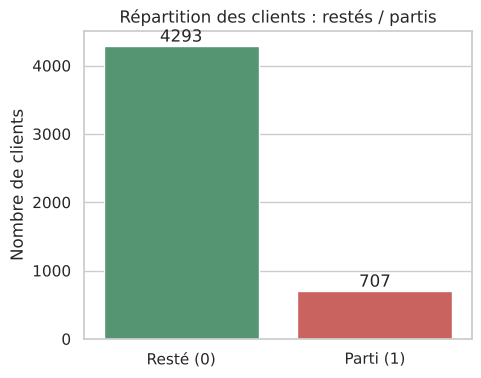

In [6]:
compte = df['churn'].value_counts().rename({0: "Resté (0)", 1: "Parti (1)"})
pourcentage = (df['churn'].value_counts(normalize=True) * 100).round(1)
print(pd.DataFrame({"Nombre": compte, "Pourcentage (%)": pourcentage.values}))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x='churn', data=df, palette=["#4C9F70", "#D9534F"])
ax.set_xticklabels(["Resté (0)", "Parti (1)"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.title("Répartition des clients : restés / partis")
plt.xlabel("")
plt.ylabel("Nombre de clients")
plt.show()

**⚠️ Attention : les classes sont déséquilibrées.** Seulement environ **14 %** des clients sont partis.
Un modèle qui répondrait toujours « le client reste » aurait déjà ~86 % de précision, mais il ne servirait à rien.
Pour bien juger les modèles, on regardera donc aussi le **rappel**, le **F1-score** et l'**AUC**, pas seulement l'accuracy.

## 6. 📊 Analyse des variables

### 6.1 Distribution des variables numériques

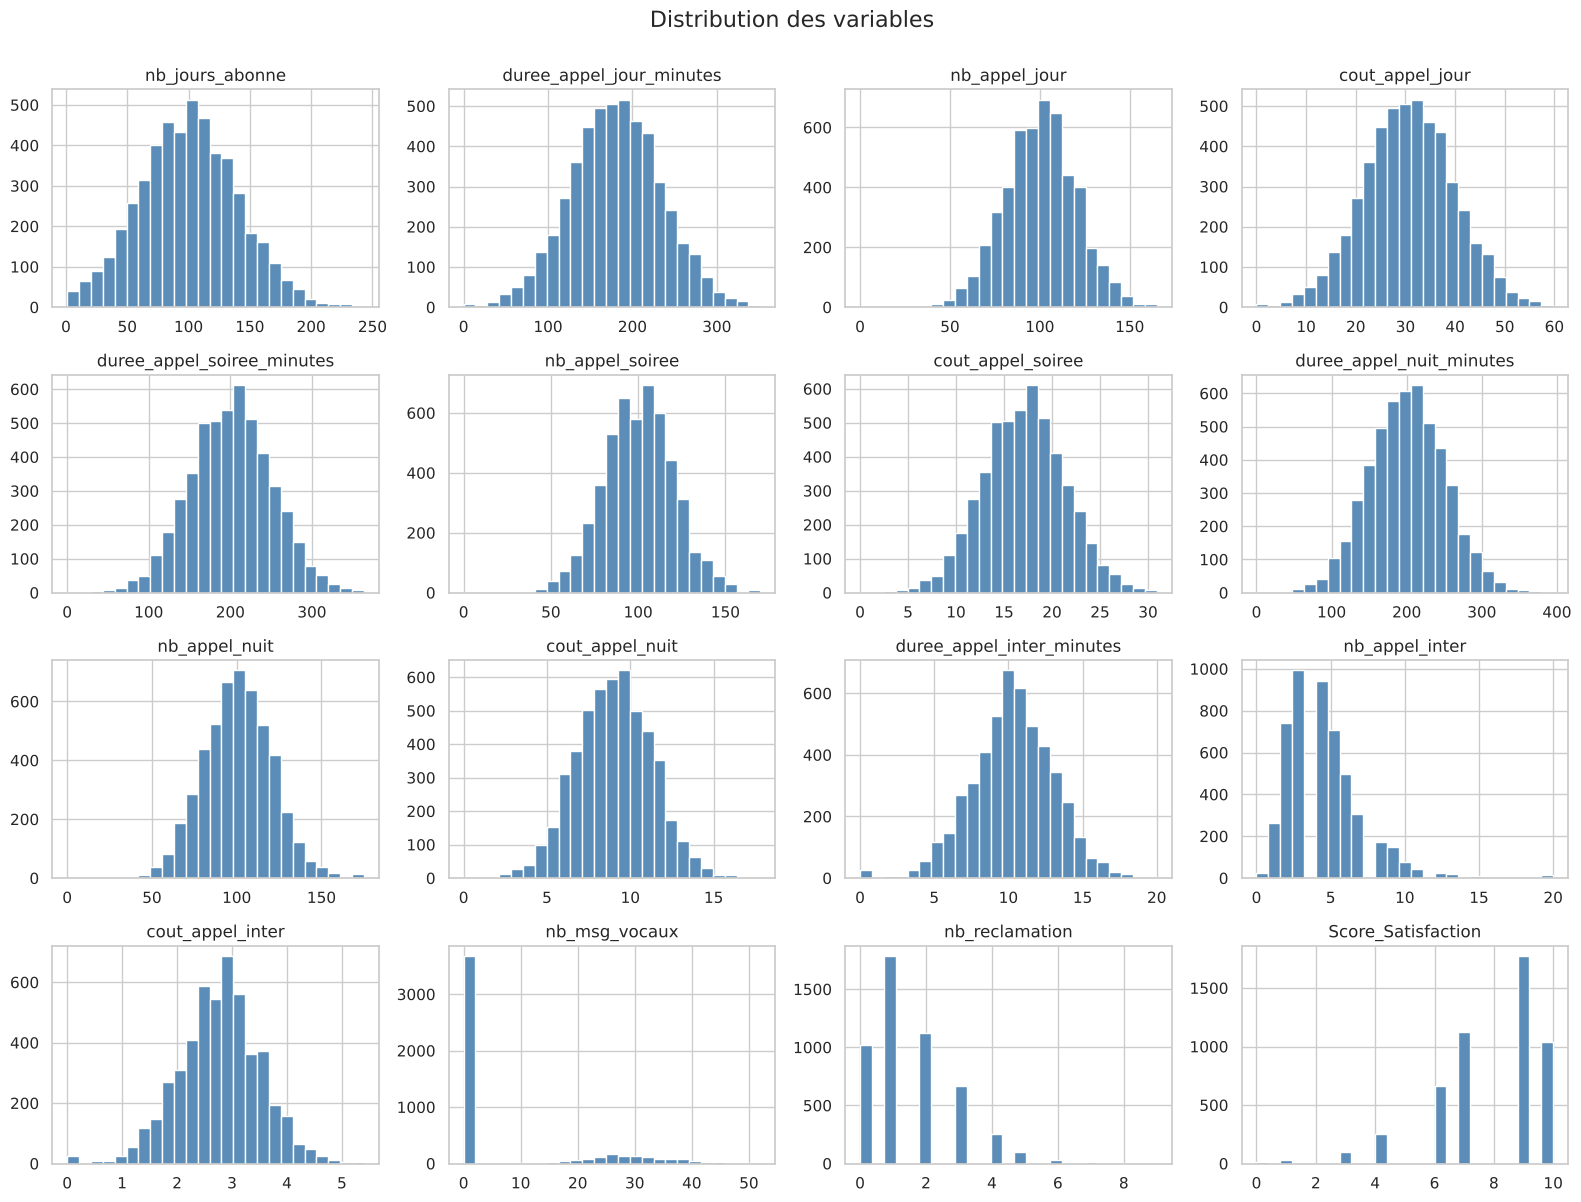

In [7]:
variables = [c for c in df.columns if c not in ['id_client', 'churn']]

df[variables].hist(bins=25, figsize=(16, 12), color="#5B8DB8", edgecolor="white")
plt.suptitle("Distribution des variables", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

### 6.2 Comparaison entre clients restés et clients partis

In [8]:
# Moyenne de chaque variable selon le churn
comparaison = df.groupby('churn')[variables].mean().T.round(2)
comparaison.columns = ["Resté (0)", "Parti (1)"]
comparaison["Écart (%)"] = ((comparaison["Parti (1)"] / comparaison["Resté (0)"] - 1) * 100).round(1)
comparaison.sort_values("Écart (%)", ascending=False)

,Resté (0),Parti (1),Écart (%)
nb_reclamation,1.46,2.25,54.1
duree_appel_jour_minutes,175.75,207.87,18.3
cout_appel_jour,29.88,35.34,18.3
cout_appel_soiree,16.90,18.00,6.5
duree_appel_soiree_minutes,198.81,211.76,6.5
cout_appel_inter,2.75,2.89,5.1
duree_appel_inter_minutes,10.19,10.69,4.9
duree_appel_nuit_minutes,199.46,206.08,3.3
cout_appel_nuit,8.98,9.27,3.2
nb_jours_abonne,99.94,102.33,2.4


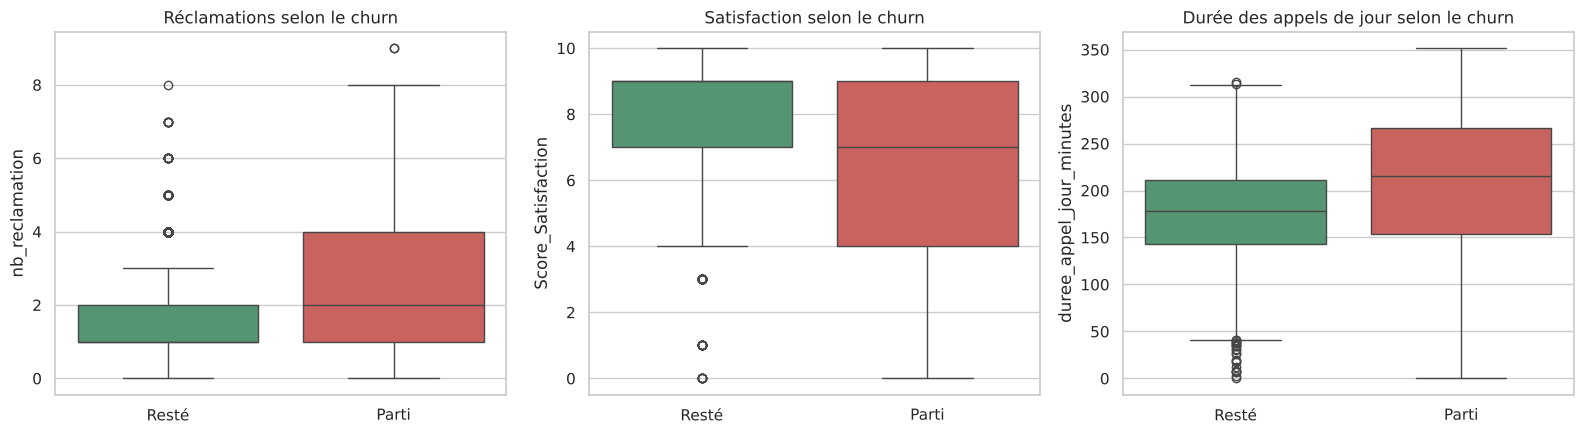

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.boxplot(x='churn', y='nb_reclamation', data=df, ax=axes[0], palette=["#4C9F70", "#D9534F"])
axes[0].set_title("Réclamations selon le churn")

sns.boxplot(x='churn', y='Score_Satisfaction', data=df, ax=axes[1], palette=["#4C9F70", "#D9534F"])
axes[1].set_title("Satisfaction selon le churn")

sns.boxplot(x='churn', y='duree_appel_jour_minutes', data=df, ax=axes[2], palette=["#4C9F70", "#D9534F"])
axes[2].set_title("Durée des appels de jour selon le churn")

for ax in axes:
    ax.set_xticklabels(["Resté", "Parti"])
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

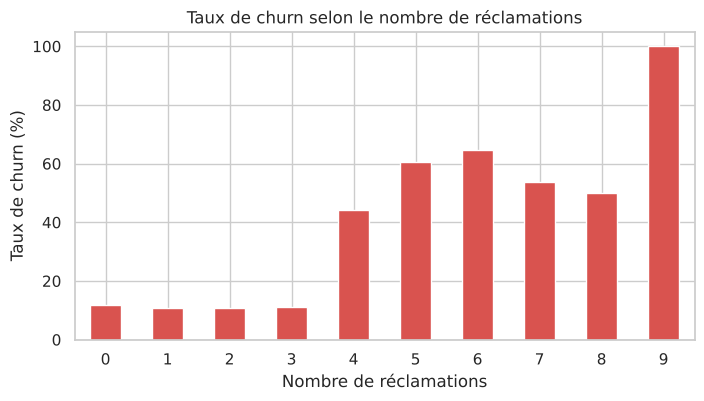

In [10]:
# Taux de churn selon le nombre de réclamations
taux = df.groupby('nb_reclamation')['churn'].mean() * 100
plt.figure(figsize=(8, 4))
taux.plot(kind='bar', color="#D9534F")
plt.title("Taux de churn selon le nombre de réclamations")
plt.xlabel("Nombre de réclamations")
plt.ylabel("Taux de churn (%)")
plt.xticks(rotation=0)
plt.show()

### 6.3 Corrélation entre les variables

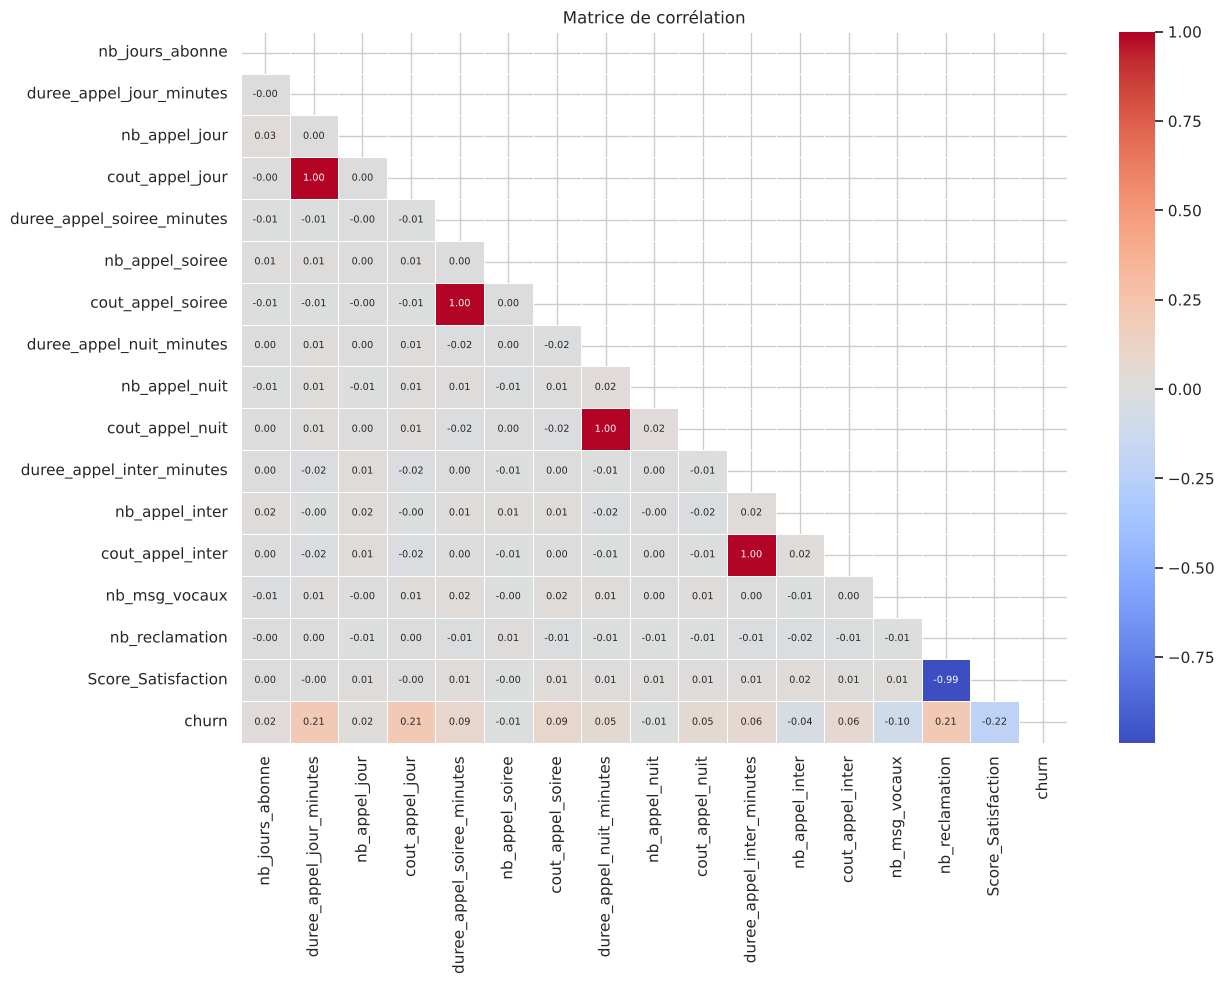

Corrélation de chaque variable avec le churn :


Score_Satisfaction           -0.218
nb_reclamation                0.213
cout_appel_jour               0.208
duree_appel_jour_minutes      0.208
nb_msg_vocaux                -0.098
duree_appel_soiree_minutes    0.089
cout_appel_soiree             0.089
duree_appel_inter_minutes     0.063
cout_appel_inter              0.063
duree_appel_nuit_minutes      0.046
cout_appel_nuit               0.045
nb_appel_inter               -0.044
nb_jours_abonne               0.021
nb_appel_jour                 0.016
nb_appel_nuit                -0.008
nb_appel_soiree              -0.008
Name: churn, dtype: float64

In [11]:
plt.figure(figsize=(13, 10))
corr = df[variables + ['churn']].corr()
masque = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, annot_kws={"size": 7})
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

print("Corrélation de chaque variable avec le churn :")
corr['churn'].drop('churn').sort_values(key=abs, ascending=False).round(3)

**Lecture** : certaines variables sont très liées entre elles. Par exemple, la **durée** d'un appel et son **coût** sont presque identiques (le coût dépend de la durée).
Ce n'est pas grave pour les arbres, mais pour la régression logistique il faut garder cela en tête.

## 7. 🧹 Préparation des données

Étapes :
1. Choisir les **variables prédictives** (X) et la **cible** (y)
2. Séparer en **80 % entraînement** / **20 % test**
3. Mettre les variables à la même échelle (utile pour KNN et la régression logistique)

> On utilise `stratify=y` pour garder la même proportion de clients partis (~14 %) dans l'entraînement et dans le test.

In [12]:
X = df[variables]       # variables prédictives
y = df['churn']         # cible

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Entraînement :", X_train.shape, "| % de churn :", round(y_train.mean()*100, 1))
print("Test         :", X_test.shape,  "| % de churn :", round(y_test.mean()*100, 1))

Entraînement : (4000, 16) | % de churn : 14.2
Test         : (1000, 16) | % de churn : 14.1


La **standardisation** (`StandardScaler`) est mise dans un **Pipeline** avec le modèle.
Avantage : le scaler apprend uniquement sur les données d'entraînement, donc **pas de fuite d'information** vers le test.

## 8. 🤖 Modélisation

On teste **4 modèles** classiques :

| Modèle | Idée simple |
|---|---|
| Régression logistique | Calcule une probabilité à partir d'une formule linéaire |
| KNN | Regarde les `k` clients les plus proches |
| Arbre de décision | Pose une suite de questions oui/non |
| Forêt aléatoire | Beaucoup d'arbres qui votent ensemble |

On crée d'abord deux petites fonctions pour éviter de répéter le même code.

In [13]:
resultats = {}      # on garde ici les scores de chaque modèle
modeles = {}        # on garde ici les modèles entraînés
predictions = {}    # prédictions (classe + probabilité) sur le test

def evaluer(nom, modele):
    """Calcule les scores d'un modèle sur le jeu de test et les enregistre."""
    y_pred = modele.predict(X_test)
    y_proba = modele.predict_proba(X_test)[:, 1]
    resultats[nom] = {
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Précision": precision_score(y_test, y_pred, zero_division=0),
        "Rappel":    recall_score(y_test, y_pred),
        "F1-score":  f1_score(y_test, y_pred),
        "AUC":       roc_auc_score(y_test, y_proba),
    }
    modeles[nom] = modele
    predictions[nom] = (y_pred, y_proba)
    print(f"=== {nom} ===")
    print(classification_report(y_test, y_pred, target_names=["Resté", "Parti"], zero_division=0))

def afficher_matrice(nom, couleur="Blues"):
    """Affiche la matrice de confusion d'un modèle."""
    y_pred = predictions[nom][0]
    mc = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(mc, annot=True, fmt='d', cmap=couleur,
                xticklabels=["Resté", "Parti"], yticklabels=["Resté", "Parti"])
    plt.title(f"Matrice de confusion – {nom}")
    plt.xlabel("Valeur prédite")
    plt.ylabel("Valeur réelle")
    plt.tight_layout()
    plt.show()

### 8.1 Régression logistique

=== Régression logistique ===
              precision    recall  f1-score   support

       Resté       0.87      0.99      0.93       859
       Parti       0.62      0.13      0.21       141

    accuracy                           0.87      1000
   macro avg       0.75      0.56      0.57      1000
weighted avg       0.84      0.87      0.83      1000



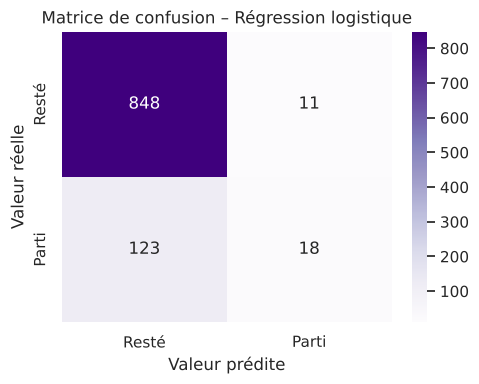

In [14]:
logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("modele", LogisticRegression(max_iter=4000, random_state=RANDOM_STATE))
])
logreg.fit(X_train, y_train)

evaluer("Régression logistique", logreg)
afficher_matrice("Régression logistique", "Purples")

### 8.2 KNN (k plus proches voisins)

D'abord, on cherche le meilleur nombre de voisins `k` avec la validation croisée.

Meilleur k (selon le F1-score) : 5


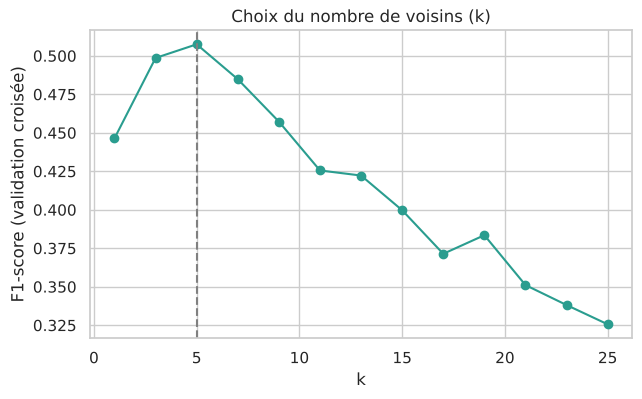

In [15]:
valeurs_k = range(1, 26, 2)
scores_k = []
for k in valeurs_k:
    pipe = Pipeline([("scaler", StandardScaler()), ("modele", KNeighborsClassifier(n_neighbors=k))])
    from sklearn.model_selection import cross_val_score
    scores_k.append(cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1").mean())

meilleur_k = list(valeurs_k)[int(np.argmax(scores_k))]
print("Meilleur k (selon le F1-score) :", meilleur_k)

plt.figure(figsize=(7, 4))
plt.plot(list(valeurs_k), scores_k, 'o-', color="#2A9D8F")
plt.axvline(meilleur_k, color="gray", linestyle="--")
plt.title("Choix du nombre de voisins (k)")
plt.xlabel("k")
plt.ylabel("F1-score (validation croisée)")
plt.show()

=== KNN ===
              precision    recall  f1-score   support

       Resté       0.90      0.98      0.94       859
       Parti       0.74      0.35      0.47       141

    accuracy                           0.89      1000
   macro avg       0.82      0.66      0.71      1000
weighted avg       0.88      0.89      0.87      1000



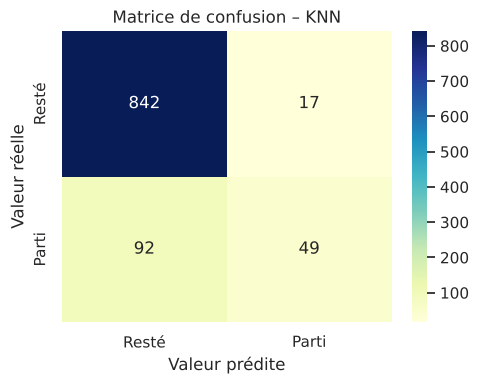

In [16]:
knn = Pipeline([
    ("scaler", StandardScaler()),
    ("modele", KNeighborsClassifier(n_neighbors=meilleur_k))
])
knn.fit(X_train, y_train)

evaluer("KNN", knn)
afficher_matrice("KNN", "YlGnBu")

### 8.3 Arbre de décision

On utilise `GridSearchCV` pour trouver la meilleure profondeur (`max_depth`). Un arbre trop profond apprend « par cœur » (surapprentissage).

Meilleurs paramètres : {'max_depth': 5}
Meilleur F1 (validation croisée) : 0.643
=== Arbre de décision ===
              precision    recall  f1-score   support

       Resté       0.92      0.98      0.95       859
       Parti       0.83      0.48      0.61       141

    accuracy                           0.91      1000
   macro avg       0.87      0.73      0.78      1000
weighted avg       0.91      0.91      0.90      1000



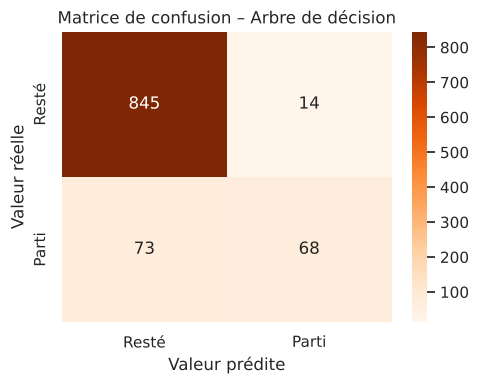

In [17]:
grille = {"max_depth": [3, 4, 5, 6, 7, 8, 9, 10]}
recherche = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                         grille, cv=5, scoring="f1", n_jobs=-1)
recherche.fit(X_train, y_train)

print("Meilleurs paramètres :", recherche.best_params_)
print("Meilleur F1 (validation croisée) :", round(recherche.best_score_, 3))

arbre = recherche.best_estimator_
evaluer("Arbre de décision", arbre)
afficher_matrice("Arbre de décision", "Oranges")

### 8.4 Forêt aléatoire

=== Forêt aléatoire ===
              precision    recall  f1-score   support

       Resté       0.93      0.99      0.96       859
       Parti       0.92      0.56      0.70       141

    accuracy                           0.93      1000
   macro avg       0.93      0.78      0.83      1000
weighted avg       0.93      0.93      0.92      1000



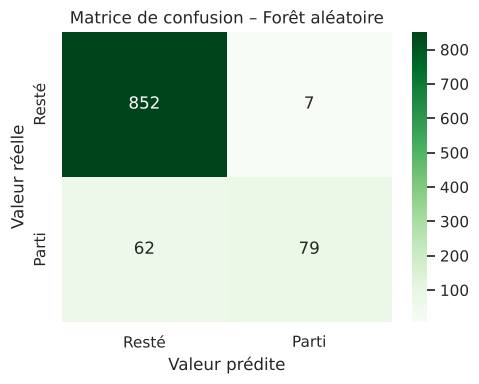

In [18]:
foret = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1)
foret.fit(X_train, y_train)

evaluer("Forêt aléatoire", foret)
afficher_matrice("Forêt aléatoire", "Greens")

## 9. 🏆 Comparaison des modèles

On compare tous les modèles sur le **même jeu de test**.

- **Accuracy** : part des prédictions correctes
- **Précision** : parmi les clients prédits « partis », combien sont vraiment partis
- **Rappel** : parmi les clients vraiment partis, combien le modèle en a trouvé
- **F1-score** : équilibre entre précision et rappel
- **AUC** : capacité du modèle à séparer les deux classes (1 = parfait, 0.5 = hasard)

In [19]:
tableau = pd.DataFrame(resultats).T.round(3).sort_values("F1-score", ascending=False)
tableau

,Accuracy,Précision,Rappel,F1-score,AUC
Forêt aléatoire,0.931,0.919,0.560,0.696,0.875
Arbre de décision,0.913,0.829,0.482,0.610,0.820
KNN,0.891,0.742,0.348,0.473,0.764
Régression logistique,0.866,0.621,0.128,0.212,0.757


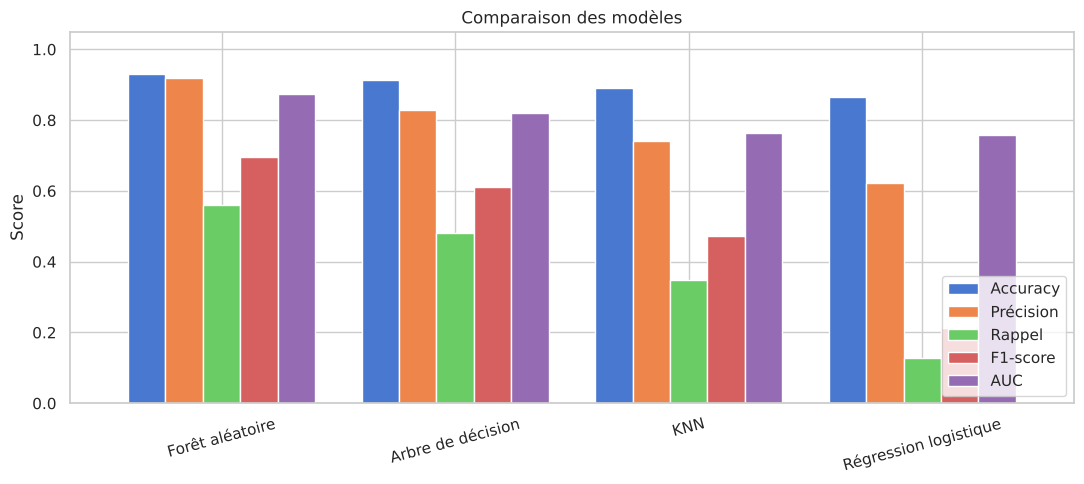

In [20]:
tableau[["Accuracy", "Précision", "Rappel", "F1-score", "AUC"]].plot(
    kind="bar", figsize=(11, 5), width=0.8)
plt.title("Comparaison des modèles")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Courbes ROC

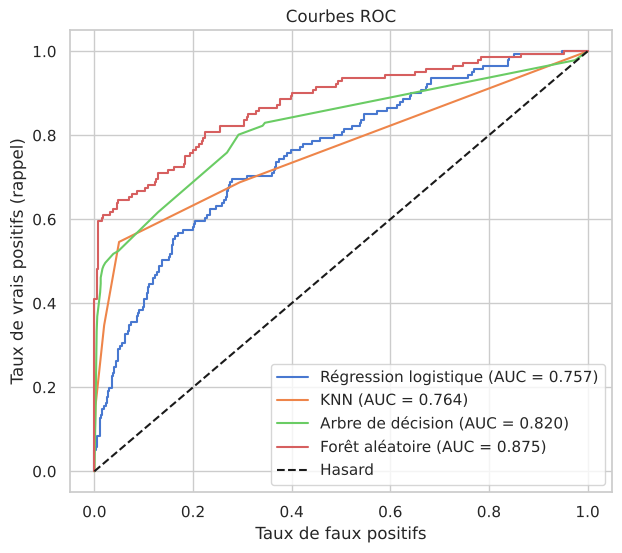

In [21]:
plt.figure(figsize=(7, 6))
for nom, (_, proba) in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Hasard")
plt.title("Courbes ROC")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs (rappel)")
plt.legend(loc="lower right")
plt.show()

In [22]:
meilleur_nom = tableau.index[0]
print("Meilleur modèle selon le F1-score :", meilleur_nom)

Meilleur modèle selon le F1-score : Forêt aléatoire


## 10. 📈 Courbes d'apprentissage

Une courbe d'apprentissage montre si le modèle **apprend bien** :
- si les deux courbes sont proches → bon équilibre
- si la courbe d'entraînement est très au-dessus de celle de validation → **surapprentissage**

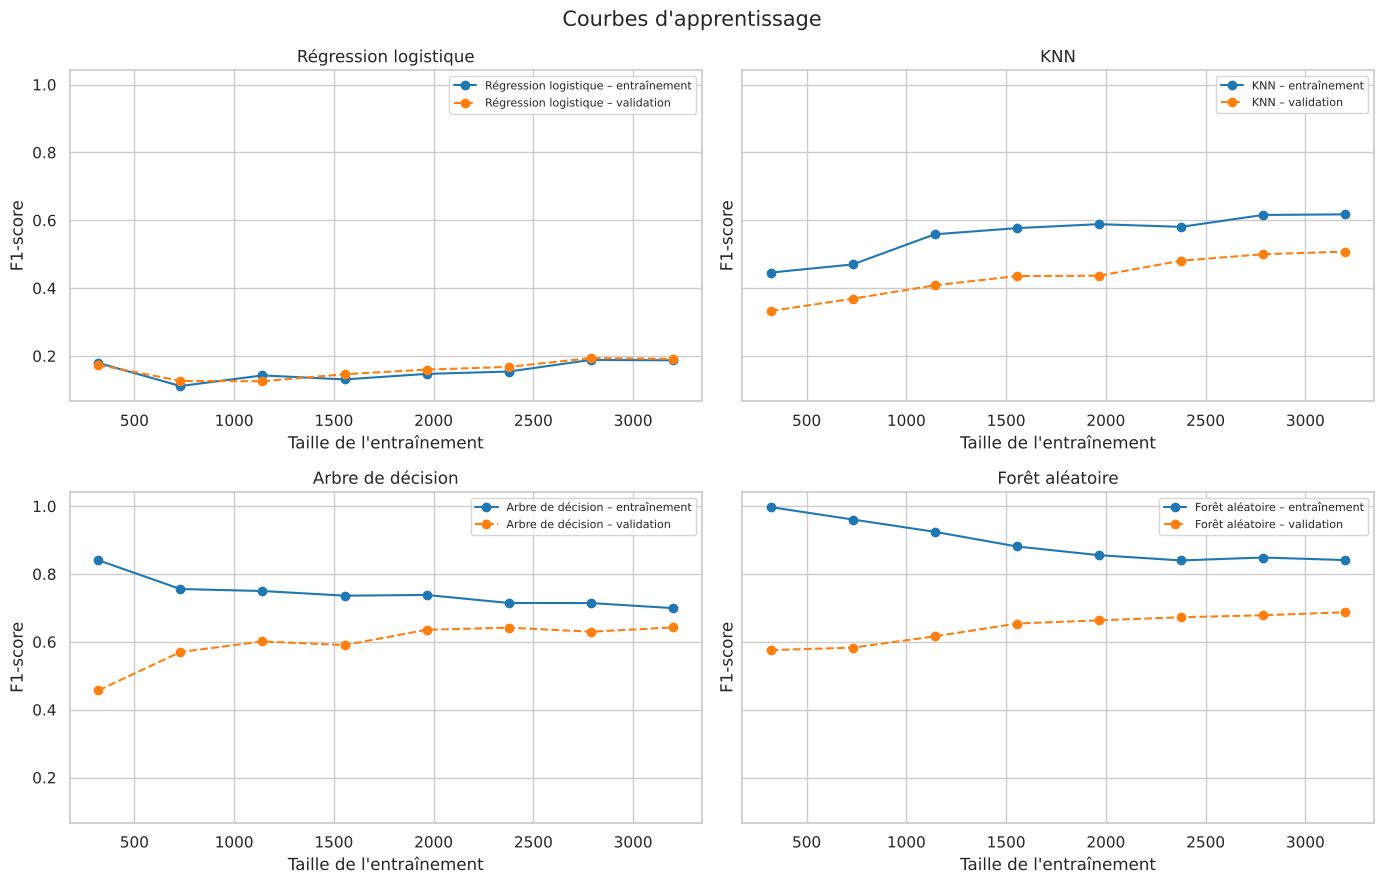

In [23]:
def courbe_apprentissage(nom, modele, couleur_train="#1f77b4", couleur_val="#ff7f0e"):
    tailles, sc_train, sc_val = learning_curve(
        modele, X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 8),
        cv=5, scoring="f1", n_jobs=-1)
    plt.plot(tailles, sc_train.mean(axis=1), 'o-', color=couleur_train, label=f"{nom} – entraînement")
    plt.plot(tailles, sc_val.mean(axis=1), 'o--', color=couleur_val, label=f"{nom} – validation")

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
for ax, (nom, modele) in zip(axes.ravel(), modeles.items()):
    plt.sca(ax)
    courbe_apprentissage(nom, modele)
    ax.set_title(nom)
    ax.set_xlabel("Taille de l'entraînement")
    ax.set_ylabel("F1-score")
    ax.legend(loc="best", fontsize=8)
plt.suptitle("Courbes d'apprentissage", fontsize=15)
plt.tight_layout()
plt.show()

## 11. 🔑 Variables les plus importantes

La forêt aléatoire peut nous dire quelles variables l'aident le plus à prédire le churn.

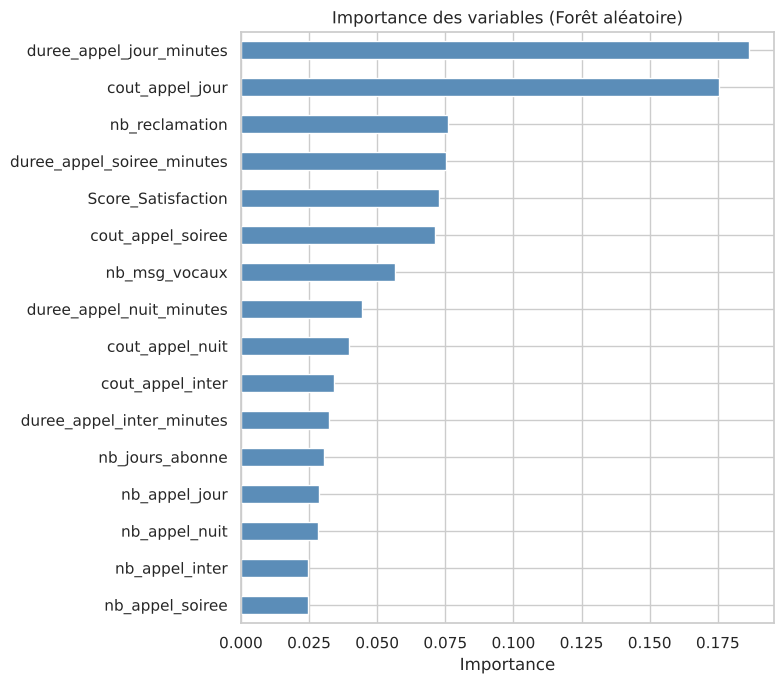

duree_appel_jour_minutes      0.186
cout_appel_jour               0.175
nb_reclamation                0.076
duree_appel_soiree_minutes    0.075
Score_Satisfaction            0.073
dtype: float64

In [24]:
importance = pd.Series(foret.feature_importances_, index=variables).sort_values()

plt.figure(figsize=(8, 7))
importance.plot(kind="barh", color="#5B8DB8")
plt.title("Importance des variables (Forêt aléatoire)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).head(5).round(3)

## 12. 💾 Sauvegarde du modèle et exemple d'utilisation

On sauvegarde le meilleur modèle dans le dossier `models/` pour pouvoir le réutiliser **sans le ré-entraîner**.

In [25]:
meilleur_modele = modeles[meilleur_nom]
joblib.dump(meilleur_modele, "../models/meilleur_modele_churn.pkl")
print(f"Modèle sauvegardé : {meilleur_nom} → models/meilleur_modele_churn.pkl")

Modèle sauvegardé : Forêt aléatoire → models/meilleur_modele_churn.pkl


In [26]:
# Exemple : recharger le modèle et prédire pour 5 clients du jeu de test
modele_charge = joblib.load("../models/meilleur_modele_churn.pkl")

exemples = X_test.head(5)
proba = modele_charge.predict_proba(exemples)[:, 1]
resultat = pd.DataFrame({
    "Probabilité de churn": (proba * 100).round(1),
    "Prédiction": np.where(proba >= 0.5, "Va partir", "Reste"),
    "Réalité": np.where(y_test.head(5).values == 1, "Parti", "Resté"),
})
resultat

,Probabilité de churn,Prédiction,Réalité
0,2.0,Reste,Resté
1,5.0,Reste,Resté
2,20.3,Reste,Resté
3,11.2,Reste,Resté
4,89.9,Va partir,Parti


## 13. ✅ Conclusion

In [27]:
meilleurs = tableau.iloc[0]
print(f"Meilleur modèle : {meilleur_nom}")
print(f"  - Accuracy : {meilleurs['Accuracy']:.1%}")
print(f"  - Rappel   : {meilleurs['Rappel']:.1%}  (clients partis correctement détectés)")
print(f"  - F1-score : {meilleurs['F1-score']:.3f}")
print(f"  - AUC      : {meilleurs['AUC']:.3f}")

Meilleur modèle : Forêt aléatoire
  - Accuracy : 93.1%
  - Rappel   : 56.0%  (clients partis correctement détectés)
  - F1-score : 0.696
  - AUC      : 0.875


### Ce qu'on retient
- Le jeu de données est **déséquilibré** (~14 % de churn) : l'accuracy seule ne suffit pas, il faut regarder le **rappel**, le **F1** et l'**AUC**.
- Les modèles basés sur des **arbres** (arbre de décision, forêt aléatoire) donnent les meilleurs résultats sur ces données.
- Les variables liées aux **réclamations**, à la **satisfaction** et à l'**usage des appels** sont les plus utiles pour repérer un client qui risque de partir.

### Pistes d'amélioration
- Utiliser `class_weight="balanced"` ou une méthode de rééquilibrage (SMOTE)
- Tester d'autres modèles (XGBoost, Gradient Boosting)
- Ajuster le **seuil de décision** (0.5 par défaut) pour trouver plus de clients à risque
- Retirer les variables très corrélées (par exemple garder la durée **ou** le coût)